# ETL standardization audit

Diff each dataset's stage-B (canonical, pre-standardization) GMT against its stage-C
(post-standardization) GMT to show what `filter_to_human_pc` actually does to the data:
renames (alias → current NCBI gene_info.gz's Symbol column, uppercased via NCBI synonyms) and drops
(non-PC + non-human/mouse organisms).

In [70]:
%matplotlib inline
import sys, gzip
from pathlib import Path
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / 'etl' / 'inputs') if Path.cwd().name == 'etl' else str(Path.cwd() / 'db' / 'etl' / 'inputs'))
from _utils import (
    DRUG_INTERMEDIATE, GENE_INTERMEDIATE, DRUG_OUTPUT, GENE_OUTPUT, CACHE_DIR,
    _pc_alias_map,
)

print('Loading NCBI gene_info + HGNC prev_symbol (cached)...')
lookup = _pc_alias_map('Mammalia/Homo_sapiens', CACHE_DIR)
print(f'  Human PC alias map size: {len(lookup):,}')

from maayanlab_bioinformatics.harmonization.ncbi_genes import ncbi_genes_fetch

_pc_df = ncbi_genes_fetch(organism='Mammalia/Homo_sapiens', cache_dir=str(CACHE_DIR))
_alias_to_syms = defaultdict(set)
for _, row in _pc_df.iterrows():
    sym = row['Symbol'].upper()
    for s in row['All_synonyms']:
        _alias_to_syms[s.upper()].add(sym)
ambiguous_set = {a for a, syms in _alias_to_syms.items() if len(syms) > 1 and a not in syms}
print(f'  Ambiguous aliases (would have been omitted from lookup): {len(ambiguous_set):,}')

_non_pc_df = ncbi_genes_fetch(
    organism='Mammalia/Homo_sapiens',
    filters=lambda d: d['type_of_gene'] != 'protein-coding',
    cache_dir=str(CACHE_DIR),
)
non_pc_set = {row['Symbol'].upper() for _, row in _non_pc_df.iterrows()} | {
    s.upper() for _, row in _non_pc_df.iterrows() for s in row['All_synonyms']
}
print(f'  Non-PC symbols (lncRNA, pseudogene, snoRNA, etc.): {len(non_pc_set):,}')

SUPPORTED_ORGS = {'homo sapiens', 'human', 'mus musculus', 'mouse'}

Loading NCBI gene_info + HGNC prev_symbol (cached)...
  Human PC alias map size: 300,947
  Ambiguous aliases (would have been omitted from lookup): 4,379
  Non-PC symbols (lncRNA, pseudogene, snoRNA, etc.): 519,336


In [71]:
def _organism_of(term):
    body = term.rsplit(' ', 1)[0]
    parts = body.split('::')
    for p in parts[5:9]:
        s = p.strip().lower()
        if s in SUPPORTED_ORGS or s in {'rattus norvegicus', 'rat', 'cow', 'bos taurus',
                                         'zebrafish', 'danio rerio', 'pig', 'sus scrofa',
                                         'dog', 'canis lupus familiaris'}:
            return s
    return 'human'

def scan_gmt(path):
    fate = Counter()
    renames = Counter()
    drops = Counter()
    n_sigs = 0
    with gzip.open(path, 'rt') as f:
        for line in f:
            if not line.strip():
                continue
            n_sigs += 1
            term = line.split('\t', 1)[0]
            org = _organism_of(term)
            org_supported = org in SUPPORTED_ORGS
            for g in line.rstrip('\n').split('\t')[2:]:
                g = g.strip().upper()
                if not g:
                    continue
                if not org_supported:
                    fate['drop_unsupp_org'] += 1
                    continue
                mapped = lookup.get(g)
                if mapped is None:
                    drops[g] += 1
                    if g in ambiguous_set:
                        fate['drop_ambiguous'] += 1
                    elif g in non_pc_set:
                        fate['drop_non_pc'] += 1
                    else:
                        fate['drop_unknown'] += 1
                elif mapped == g:
                    fate['identity'] += 1
                else:
                    fate['renamed'] += 1
                    renames[(g, mapped)] += 1
    return fate, n_sigs, renames, drops


DATASETS = []
for inter_dir, final_dir, kind in [
    (DRUG_INTERMEDIATE, DRUG_OUTPUT, 'drug'),
    (GENE_INTERMEDIATE, GENE_OUTPUT, 'gene'),
]:
    for final_path in sorted(final_dir.glob('*.gmt.gz')):
        inter_path = inter_dir / final_path.name
        DATASETS.append((kind, final_path.stem.replace('.gmt', ''), inter_path, final_path))

rows = []
renames_global = Counter()
drops_global = Counter()
inter_sig_counts = {}
final_sig_counts = {}
for kind, name, inter_path, final_path in DATASETS:
    if not inter_path.exists():
        continue
    fate, n_inter_sigs, renames, drops = scan_gmt(inter_path)
    inter_sig_counts[name] = n_inter_sigs
    renames_global.update(renames)
    drops_global.update(drops)
    if final_path.exists():
        _, n_final_sigs, _, _ = scan_gmt(final_path)
        final_sig_counts[name] = n_final_sigs
    total = sum(fate.values())
    rows.append({
        'kind': kind, 'dataset': name,
        'inter_sigs': n_inter_sigs, 'final_sigs': final_sig_counts.get(name, 0),
        'total_DEGs': total,
        'identity':         fate.get('identity', 0),
        'renamed':          fate.get('renamed', 0),
        'drop_non_pc':      fate.get('drop_non_pc', 0),
        'drop_ambiguous':   fate.get('drop_ambiguous', 0),
        'drop_unsupp_org':  fate.get('drop_unsupp_org', 0),
        'drop_unknown':     fate.get('drop_unknown', 0),
    })

df = pd.DataFrame(rows).set_index('dataset')
df

,kind,inter_sigs,final_sigs,total_DEGs,identity,renamed,drop_non_pc,drop_ambiguous,drop_unsupp_org,drop_unknown
dataset,,,,,,,,,,
creeds-chem,drug,1860,1541,563969,407377,25663,11542,801,93998,24588
deepcover-moa,drug,1748,1748,173748,169250,3803,640,0,0,55
ginkgo-bioworks,drug,9310,9310,6799872,5806508,92165,901051,0,0,148
lincs-l1000-cp,drug,156926,156926,39231500,38469032,553496,206399,2554,0,19
microarrays-cmap,drug,12197,11991,1201605,1097737,63881,33753,434,0,5800
nibr-drug-seq,drug,18810,18810,2370763,2363148,7615,0,0,0,0
rummageo-chem,drug,5345,5345,4011495,3999105,12345,0,0,0,45
sciplex,drug,4604,4604,2302000,2299408,2592,0,0,0,0
tahoe-100m,drug,105404,105404,9763011,9736846,26165,0,0,0,0


## DEG fate per dataset

For each dataset's intermediate (pre-standardization) GMT, what happens to each gene
when `filter_to_human_pc` runs? either:
- **Identity**: gene already current
- **Renamed**: gene resolved via NCBI synonyms / HGNC `prev_symbol` to a current Symbol.
- **Dropped**: gene can't be resolved (non-PC, ambiguous, or unsupported organism).

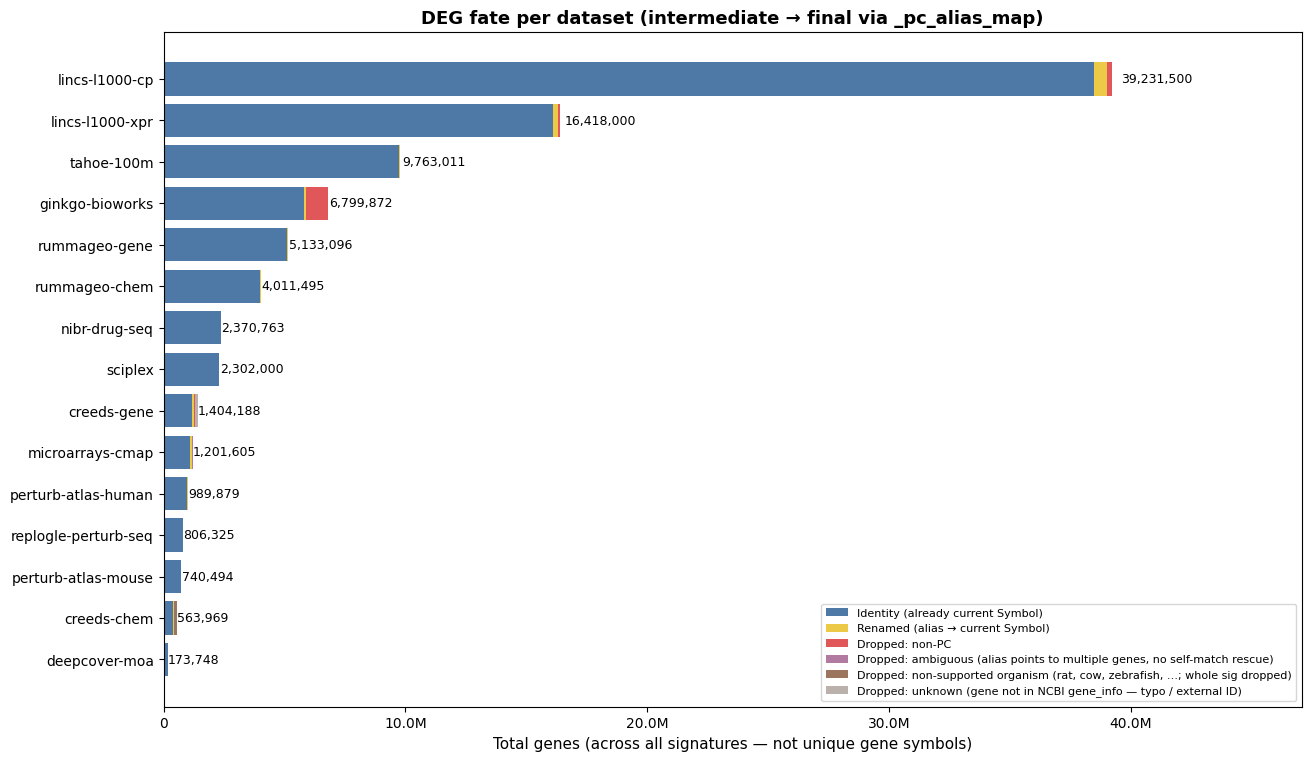

In [72]:
from matplotlib.ticker import FuncFormatter

# NOTE: these are TOTAL gene counts across all signatures in the GMT (occurrences),
# not unique gene symbols. A gene that appears in 100 signatures contributes 100 entries.
_plot_df = df[df['total_DEGs'] > 0]
names = list(_plot_df.sort_values('total_DEGs').index)
totals = [_plot_df.loc[n, 'total_DEGs'] for n in names]

def _fmt(v):
    return f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1e3:.0f}k' if v >= 1e3 else str(v)

SEGMENTS = [
    ('identity',        '#4e79a7', 'Identity (already current Symbol)'),
    ('renamed',         '#edc948', 'Renamed (alias → current Symbol)'),
    ('drop_non_pc',     '#e15759', 'Dropped: non-PC'),
    ('drop_ambiguous',  '#b07aa1', 'Dropped: ambiguous (alias points to multiple genes, no self-match rescue)'),
    ('drop_unsupp_org', '#9c755f', 'Dropped: non-supported organism (rat, cow, zebrafish, …; whole sig dropped)'),
    ('drop_unknown',    '#bab0ac', 'Dropped: unknown (gene not in NCBI gene_info — typo / external ID)'),
]

fig, ax = plt.subplots(figsize=(13, max(6, 0.5 * len(names))), constrained_layout=True)
left = [0] * len(names)
for col, color, label in SEGMENTS:
    vals = [_plot_df.loc[n, col] for n in names]
    ax.barh(names, vals, left=left, color=color, label=label)
    left = [l + v for l, v in zip(left, vals)]
# Only ONE label per row — the total at the right edge. Inline segment labels removed
# to avoid the overlap mess on small datasets.
for i, t in enumerate(totals):
    ax.text(t * 1.01, i, f'{t:,}', va='center', fontsize=9)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: _fmt(int(x))))
ax.set_xlabel('Total genes (across all signatures — not unique gene symbols)', fontsize=11)
ax.set_title('DEG fate per dataset (intermediate → final via _pc_alias_map)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.set_xlim(0, max(totals) * 1.20 if totals else 1)
ax.tick_params(axis='y', labelsize=10)
plt.show()

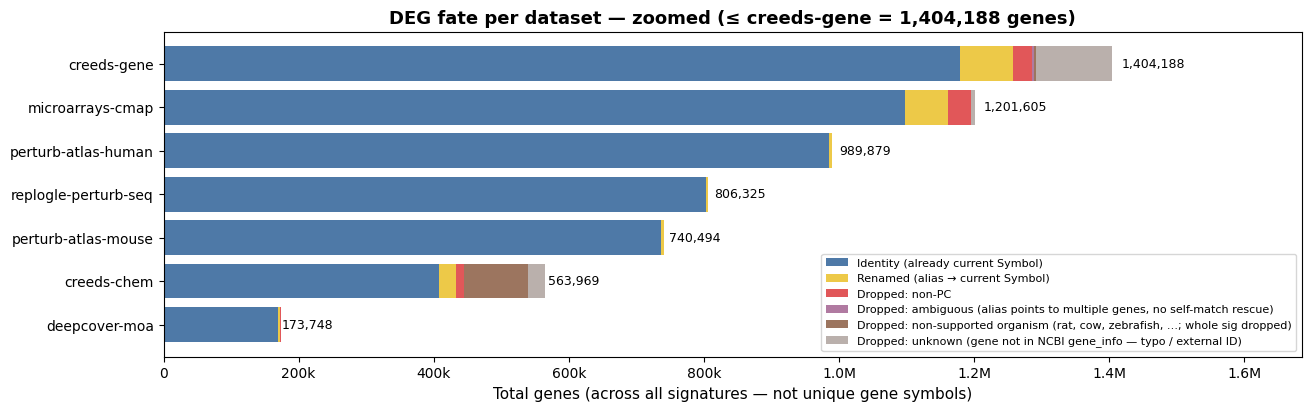

In [79]:
_cutoff = _plot_df.loc['creeds-gene', 'total_DEGs']
_small_df = _plot_df[_plot_df['total_DEGs'] <= _cutoff]
names_s = list(_small_df.sort_values('total_DEGs').index)
totals_s = [_small_df.loc[n, 'total_DEGs'] for n in names_s]

fig, ax = plt.subplots(figsize=(13, max(4, 0.55 * len(names_s))), constrained_layout=True)
left = [0] * len(names_s)
for col, color, label in SEGMENTS:                          # SEGMENTS reused from cell above
    vals = [_small_df.loc[n, col] for n in names_s]
    ax.barh(names_s, vals, left=left, color=color, label=label)
    left = [l + v for l, v in zip(left, vals)]
for i, t in enumerate(totals_s):
    ax.text(t * 1.01, i, f'{t:,}', va='center', fontsize=9)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: _fmt(int(x))))
ax.set_xlabel('Total genes (across all signatures — not unique gene symbols)', fontsize=11)
ax.set_title(f'DEG fate per dataset — zoomed (≤ creeds-gene = {_cutoff:,} genes)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.set_xlim(0, max(totals_s) * 1.20 if totals_s else 1)
ax.tick_params(axis='y', labelsize=10)
plt.show()

## Signature count: intermediate vs final

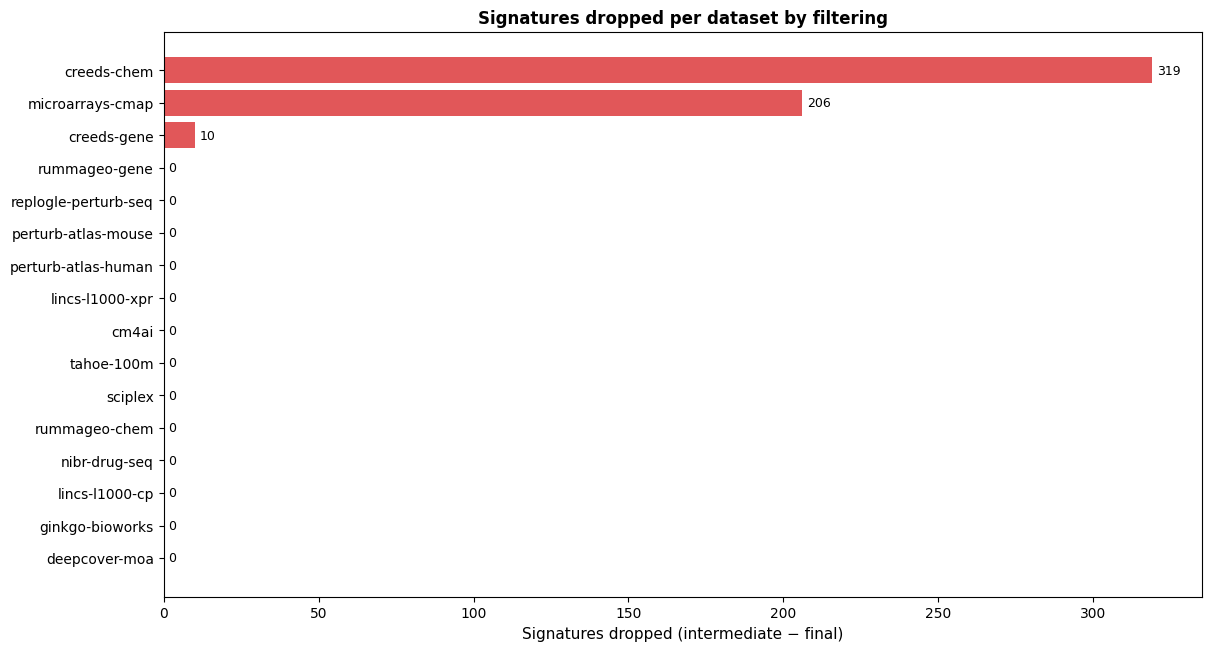

In [80]:
dropped = {n: df.loc[n, 'inter_sigs'] - df.loc[n, 'final_sigs'] for n in df.index}
names_s = sorted(dropped, key=dropped.get)
drop_v = [dropped[n] for n in names_s]

fig, ax = plt.subplots(figsize=(12, max(4, 0.4 * len(names_s))), constrained_layout=True)
ax.barh(names_s, drop_v, color='#e15759')
for i, v in enumerate(drop_v):
    ax.text(v + max(drop_v) * 0.005 if drop_v else 0, i, f'{v:,}', va='center', fontsize=9)
ax.set_xlabel('Signatures dropped (intermediate − final)', fontsize=11)
ax.set_title('Signatures dropped per dataset by filtering',
             fontsize=12, fontweight='bold')
ax.tick_params(axis='y', labelsize=10)
plt.show()

## DEG type composition: intermediate vs final

In [ ]:
pc_current_set = set(lookup.values())                  # current official PC Symbols (uppercase)
pc_alias_set   = set(lookup) - pc_current_set          # deprecated aliases that map to a current PC

def gene_type_counts(path):
    """Return (current_PC, drift_recoverable, non_PC) for unique DEG symbols in a GMT."""
    with gzip.open(path, 'rt') as f:
        genes = {g.strip().upper() for line in f if line.strip() for g in line.split('\t')[2:] if g.strip()}
    pc = sum(1 for g in genes if g in pc_current_set)
    drift = sum(1 for g in genes if g in pc_alias_set)
    return pc, drift, len(genes) - pc - drift

inter_counts = {}
final_counts = {}
for kind, name, inter_path, final_path in DATASETS:
    if inter_path.exists():
        inter_counts[name] = gene_type_counts(inter_path)
    if final_path.exists():
        final_counts[name] = gene_type_counts(final_path)

names_g = sorted(set(inter_counts) & set(final_counts), key=lambda n: sum(inter_counts.get(n, (0,0,0))))
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
COLORS = [('#4e79a7', 'Current protein-coding'),
          ('#edc948', 'Drift-recoverable (deprecated alias of PC)'),
          ('#e15759', 'Non-protein-coding')]

for ax, (counts, title) in zip(axes, [(inter_counts, 'Intermediate (pre-filtering)'),
                                       (final_counts, 'Final (post-filtering and name standardization)')]):
    pc_v   = [counts[n][0] for n in names_g]
    drift_v= [counts[n][1] for n in names_g]
    npc_v  = [counts[n][2] for n in names_g]
    totals_g = [sum(counts[n]) for n in names_g]
    MIN_LABEL = max(totals_g) // 80 if totals_g else 1
    left = [0] * len(names_g)
    # Only the first segment (Current protein-coding) gets inline value labels;
    # drift-recoverable + non-PC stay unlabeled to keep things readable.
    for seg_idx, (vals, (color, label)) in enumerate(zip([pc_v, drift_v, npc_v], COLORS)):
        ax.barh(names_g, vals, left=left, color=color, label=label)
        if seg_idx == 0:
            for i, v in enumerate(vals):
                if v >= MIN_LABEL:
                    ax.text(left[i] + v / 2, i, f'{v:,}', va='center', ha='center',
                            fontsize=7, color='white', fontweight='bold')
        left = [l + v for l, v in zip(left, vals)]
    for i, t in enumerate(totals_g):
        ax.text(t * 1.01, i, f'{t:,}', va='center', fontsize=8)
    ax.set_xlabel('Unique DEG symbols', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(totals_g) * 1.18 if totals_g else 1)

axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

NameError: name 'lookup' is not defined

## Top global renames (alias → current Symbol)

Most-frequent rename events across the entire pipeline. DEGs rewritten to its current NCBI official Symbol so that the same gene appears under one consistent name across datasets.

In [76]:
rename_df = pd.DataFrame(
    [(a, b, n) for (a, b), n in renames_global.most_common(50)],
    columns=['original_alias', 'current_Symbol', 'occurrences']
).set_index('original_alias')
rename_df.head(50)

,current_Symbol,occurrences
original_alias,,
FAM129A,NIBAN1,39241
HIST1H1C,H1-2,31736
METTL7A,TMT1A,31241
HIST1H2AC,H2AC6,27627
H1F0,H1-0,27388
HIST1H2BD,H2BC5,23667
C3ORF14,CEP15,22585
HIST1H2BK,H2BC12,19498
NDUFA4L2,COXFA4L2,17449


## Top dropped genes

These genes appeared in DEG lists but couldn't be resolved by `_pc_alias_map`. Reasons:
- Gene isn't in NCBI gene_info (typo, archaic name with no official record)
- Gene is non-protein-coding (lincRNA, pseudogene, miRNA host)
- Gene is an ambiguous alias not rescued by HGNC `prev_symbol` (e.g. `A1`, `ABP-280`)

In [77]:
def _classify_drop(g):
    """Same priority order as scan_gmt's per-gene classification."""
    if g in ambiguous_set:
        return 'ambiguous (alias points to multiple genes)'
    if g in non_pc_set:
        return 'non-PC'
    return 'unknown (not in NCBI gene_info — typo / external ID / mouse-only symbol)'

drop_df = pd.DataFrame(
    [(g, n, _classify_drop(g)) for g, n in drops_global.most_common(50)],
    columns=['dropped_gene', 'occurrences', 'reason']
).set_index('dropped_gene')
drop_df.head(50)

,occurrences,reason
dropped_gene,,
XIST,54559,non-PC
NEAT1,29401,non-PC
GUSBP3,24086,non-PC
CMAHP,18826,non-PC
MIR22HG,16652,non-PC
C6ORF48,15171,non-PC
CYP2B7P,12041,non-PC
FAM30A,10952,non-PC
LINC00623,10199,non-PC


## Ambiguous-alias drops per dataset

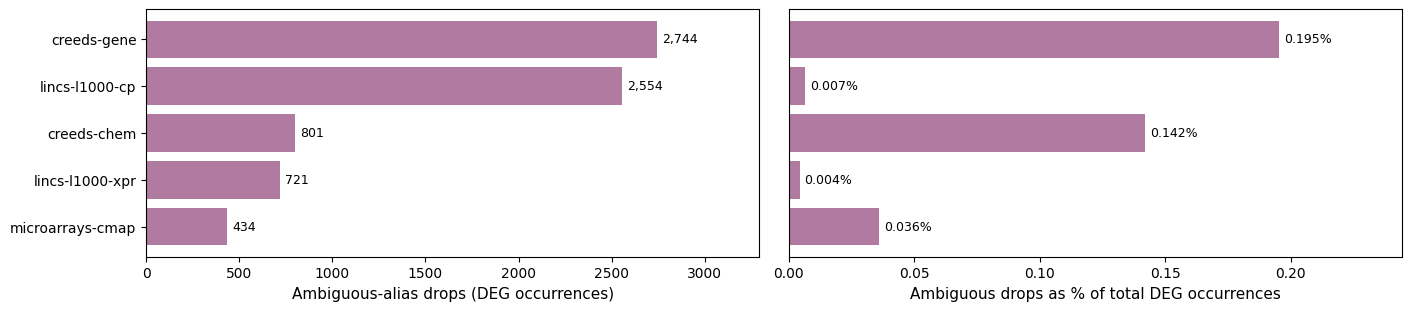

,ambiguous_drops,% of dataset
dataset,,
microarrays-cmap,434,0.036118
lincs-l1000-xpr,721,0.004392
creeds-chem,801,0.142029
lincs-l1000-cp,2554,0.006510
creeds-gene,2744,0.195415


In [82]:
_amb_df = df[df['drop_ambiguous'] > 0].copy()
_amb_df['ambig_pct'] = 100 * _amb_df['drop_ambiguous'] / _amb_df['total_DEGs']
_amb_df = _amb_df.sort_values('drop_ambiguous')

fig, axes = plt.subplots(1, 2, figsize=(14, max(3, 0.5 * len(_amb_df))), constrained_layout=True)
axes[0].barh(_amb_df.index, _amb_df['drop_ambiguous'], color='#b07aa1')
for i, v in enumerate(_amb_df['drop_ambiguous']):
    axes[0].text(v + _amb_df['drop_ambiguous'].max() * 0.01, i, f'{v:,}', va='center', fontsize=9)
axes[0].set_xlabel('Ambiguous-alias drops (DEG occurrences)', fontsize=11)
axes[0].set_xlim(0, _amb_df['drop_ambiguous'].max() * 1.20)

axes[1].barh(_amb_df.index, _amb_df['ambig_pct'], color='#b07aa1')
for i, v in enumerate(_amb_df['ambig_pct']):
    axes[1].text(v + _amb_df['ambig_pct'].max() * 0.01, i, f'{v:.3f}%', va='center', fontsize=9)
axes[1].set_xlabel('Ambiguous drops as % of total DEG occurrences', fontsize=11)
axes[1].set_xlim(0, _amb_df['ambig_pct'].max() * 1.25)
axes[1].tick_params(axis='y', left=False, labelleft=False)

plt.show()

_amb_df[['drop_ambiguous', 'ambig_pct']].rename(columns={
    'drop_ambiguous': 'ambiguous_drops',
    'ambig_pct':      '% of dataset',
})